In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# ---- Settings ----
RANDOM_STATE = 42
ZOMATO_RED = "#E23744"
GREEN = "#2E7D32"
BLUE = "#5C6BC0"
RED = "#D32F2F"

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 50, "display.width", 140)

In [28]:
import kagglehub
from pathlib import Path
import pandas as pd

KAGGLE_DATASET = "srisyra02/zomato-market-analysis"
DATA_FILE = "Zomato Restaurant Dataset.csv"

print(f"Downloading {KAGGLE_DATASET} from Kaggle...")
folder_path = kagglehub.dataset_download(KAGGLE_DATASET)
folder = Path(folder_path)

# Find the CSV file inside the downloaded folder
matches = sorted(folder.rglob(DATA_FILE)) or sorted(folder.rglob("*.csv"))
if not matches:
    raise FileNotFoundError(f"No CSV file found in {folder}")

data_path = matches[0]
raw = pd.read_csv(data_path)
print(f"Successfully loaded {data_path} -> {raw.shape[0]:,} rows, {raw.shape[1]} columns")
display(raw.head())

Using Colab cache for faster access to the 'zomato-market-analysis' dataset.
Successfully loaded /kaggle/input/zomato-market-analysis/Zomato Restaurant Dataset.csv -> 9,551 rows, 21 columns


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [29]:
COLUMN_RENAMES = {
    "restaurant_id": "id",
    "restaurant_name": "name",
    "average_cost_for_two": "cost_for_two",
    "has_table_booking": "table_booking",
    "has_online_delivery": "online_delivery",
    "is_delivering_now": "delivering_now",
    "aggregate_rating": "rating",
}

# Standard Zomato country codes
COUNTRY_NAMES = {
    1: "India", 14: "Australia", 30: "Brazil", 37: "Canada", 94: "Indonesia",
    148: "New Zealand", 162: "Philippines", 166: "Qatar", 184: "Singapore",
    189: "South Africa", 191: "Sri Lanka", 208: "Turkey", 214: "UAE",
    215: "United Kingdom", 216: "United States",
}

YES_NO_COLUMNS = ["table_booking", "online_delivery", "delivering_now"]
CHAIN_MIN_OUTLETS = 5   # a brand with this many outlets or more counts as a chain


def clean_data(raw_df):
    """Return a cleaned copy of the raw Zomato data with extra feature columns."""
    data = raw_df.copy()

    # 1) Simple column names
    data.columns = (data.columns.str.strip().str.lower()
                    .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
    data = data.rename(columns=COLUMN_RENAMES)

    # 2) Country names
    data["country"] = data["country_code"].map(COUNTRY_NAMES)
    assert data["country"].notna().all(), "Found a country code that is missing from COUNTRY_NAMES"

    # 3) Missing cuisines, and columns with only one value
    data["cuisines"] = data["cuisines"].fillna("Unknown")
    constant_cols = [c for c in data.columns if data[c].nunique() == 1]
    print("Constant columns dropped:", constant_cols)
    data = data.drop(columns=constant_cols)

    # 4) Yes/No -> True/False
    for col in YES_NO_COLUMNS:
        data[col] = data[col].str.strip().str.lower().eq("yes")

    # 5) Rated flag, valid coordinates, cuisine features
    data["is_rated"] = data["rating"] > 0
    data["valid_coords"] = ~((data["latitude"] == 0) & (data["longitude"] == 0))
    data["cuisine_list"] = data["cuisines"].apply(
        lambda s: [c.strip() for c in s.split(",")] if s != "Unknown" else []
    )
    data["n_cuisines"] = data["cuisine_list"].str.len()

    # 6) Clean currency labels (the source file has broken symbols)
    data["currency"] = data["currency"].str.replace(r"\(.*\)", "", regex=True).str.strip()
    data["currency"] = data["currency"].replace({"Pounds": "Pounds (GBP)"})

    # 7) Cost percentile inside each country, so prices in different currencies can be compared
    data["cost_pct_in_country"] = data.groupby("country")["cost_for_two"].rank(pct=True)

    # 8) Chain flag: same restaurant name appears many times
    data["outlets"] = data["name"].map(data["name"].value_counts())
    data["is_chain"] = data["outlets"] >= CHAIN_MIN_OUTLETS

    return data


df = clean_data(raw)

rated = df[df["is_rated"]].copy()          # restaurants that have a rating
india = df[df["country"] == "India"].copy()
india_rated = india[india["is_rated"]]

print(f"Clean shape: {df.shape} | rated restaurants: {len(rated):,} ({len(rated) / len(df):.1%})")

Constant columns dropped: ['switch_to_order_menu']
Clean shape: (9551, 28) | rated restaurants: 7,403 (77.5%)


In [30]:
def mean_of_rated(ratings):
    """Average rating that ignores restaurants with no rating (rating = 0)."""
    return ratings[ratings > 0].mean()


def summarize(data, by, count_how="count", **extra_aggs):
    """Group the data and return restaurant count, rated count, average rating, and average votes."""
    return data.groupby(by).agg(
        restaurants=("id", count_how),
        rated=("is_rated", "sum"),
        avg_rating=("rating", mean_of_rated),
        avg_votes=("votes", "mean"),
        **extra_aggs,
    )


def add_bar_labels(ax, positions, values, offset, fmt="{:,}", **text_kwargs):
    """Write a value above each bar."""
    for pos, value in zip(positions, values):
        ax.text(pos, value + offset, fmt.format(value), ha="center", fontsize=9, **text_kwargs)

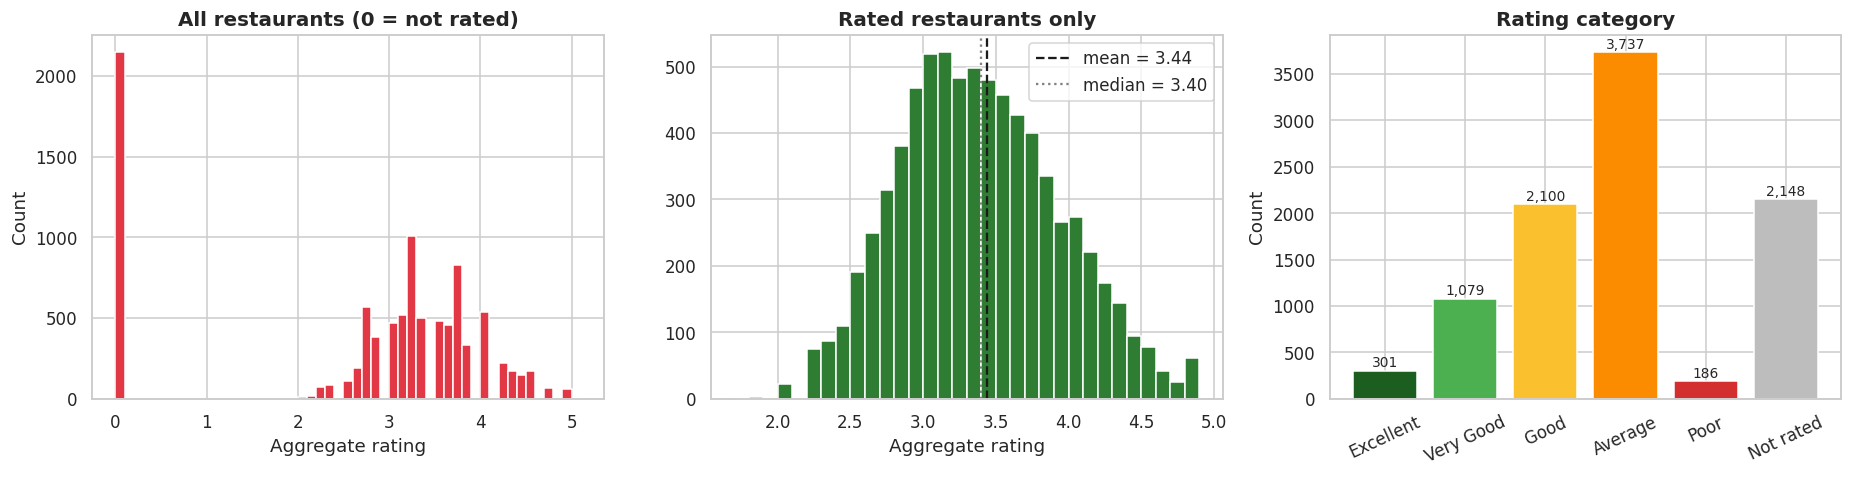

,count,mean,std,min,25%,50%,75%,max
rated restaurants,7403.0,3.44,0.552,1.8,3.0,3.4,3.8,4.9


Skewness of rated distribution: 0.23


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(df["rating"], bins=np.arange(0, 5.2, 0.1), color=ZOMATO_RED, edgecolor="white")
axes[0].set(title="All restaurants (0 = not rated)", xlabel="Aggregate rating", ylabel="Count")

axes[1].hist(rated["rating"], bins=np.arange(1.7, 5.0, 0.1), color=GREEN, edgecolor="white")
axes[1].axvline(rated["rating"].mean(), color="k", ls="--", label=f"mean = {rated['rating'].mean():.2f}")
axes[1].axvline(rated["rating"].median(), color="gray", ls=":", label=f"median = {rated['rating'].median():.2f}")
axes[1].set(title="Rated restaurants only", xlabel="Aggregate rating")
axes[1].legend()

category_order = ["Excellent", "Very Good", "Good", "Average", "Poor", "Not rated"]
category_colors = {"Excellent": "#1B5E20", "Very Good": "#4CAF50", "Good": "#FBC02D",
                   "Average": "#FB8C00", "Poor": RED, "Not rated": "#BDBDBD"}
category_counts = df["rating_text"].value_counts().reindex(category_order).dropna()
axes[2].bar(category_counts.index, category_counts.values,
            color=[category_colors[c] for c in category_counts.index])
add_bar_labels(axes[2], range(len(category_counts)), category_counts.values, offset=40)
axes[2].set(title="Rating category", ylabel="Count")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

display(rated["rating"].describe().round(3).to_frame("rated restaurants").T)
print(f"Skewness of rated distribution: {rated['rating'].skew():.2f}")

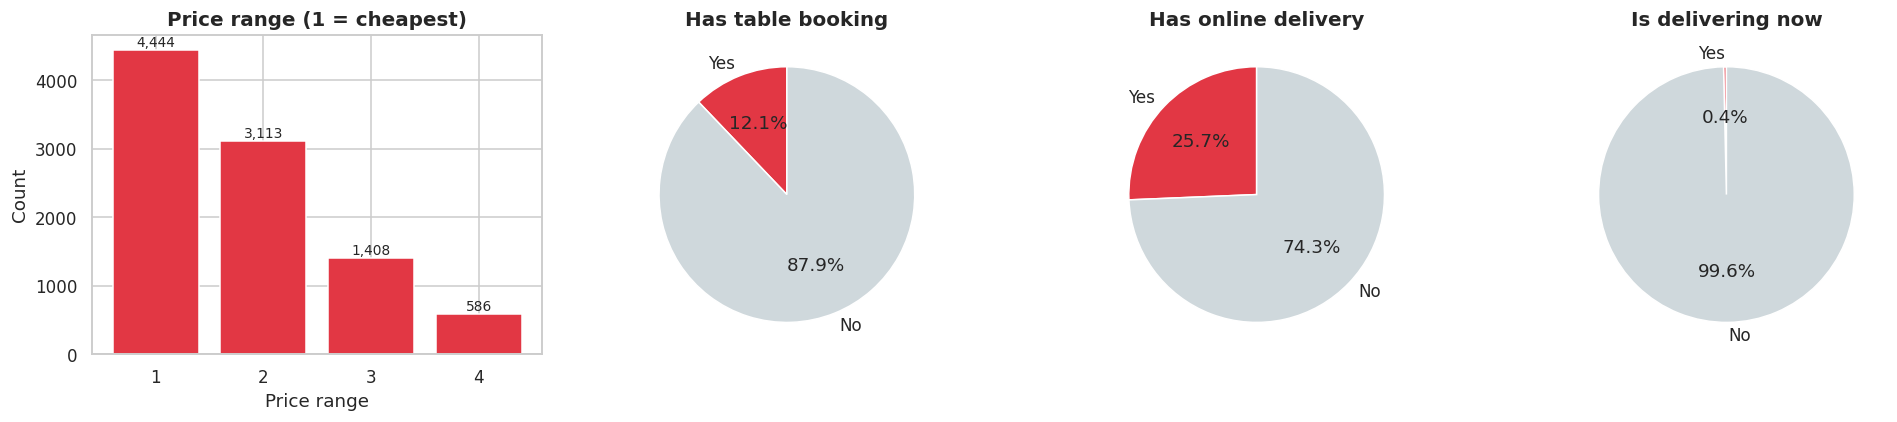

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

price_counts = df["price_range"].value_counts().sort_index()
axes[0].bar(price_counts.index.astype(str), price_counts.values, color=ZOMATO_RED)
axes[0].set(title="Price range (1 = cheapest)", xlabel="Price range", ylabel="Count")
add_bar_labels(axes[0], range(len(price_counts)), price_counts.values, offset=50)

service_titles = {"table_booking": "Has table booking",
                  "online_delivery": "Has online delivery",
                  "delivering_now": "Is delivering now"}
for ax, (col, title) in zip(axes[1:], service_titles.items()):
    yes_no = df[col].value_counts().reindex([True, False])
    ax.pie(yes_no.values, labels=["Yes", "No"], autopct="%1.1f%%", colors=[ZOMATO_RED, "#CFD8DC"],
           startangle=90, wedgeprops={"edgecolor": "white"})
    ax.set_title(title)

plt.tight_layout()
plt.show()

,restaurants,rated,avg_rating,avg_votes,online_delivery,table_booking,share_%
country,,,,,,,
India,8652,6513,3.35,137.21,0.28,0.13,90.59
United States,434,431,4.03,428.22,0.00,0.00,4.54
United Kingdom,80,79,4.14,205.49,0.00,0.15,0.84
UAE,60,60,4.23,493.52,0.47,0.30,0.63
South Africa,60,60,4.21,315.17,0.00,0.03,0.63
Brazil,60,55,4.11,19.62,0.00,0.00,0.63
New Zealand,40,40,4.26,243.02,0.00,0.00,0.42
Turkey,34,34,4.30,431.47,0.00,0.00,0.36
Australia,24,24,3.66,111.42,0.00,0.00,0.25


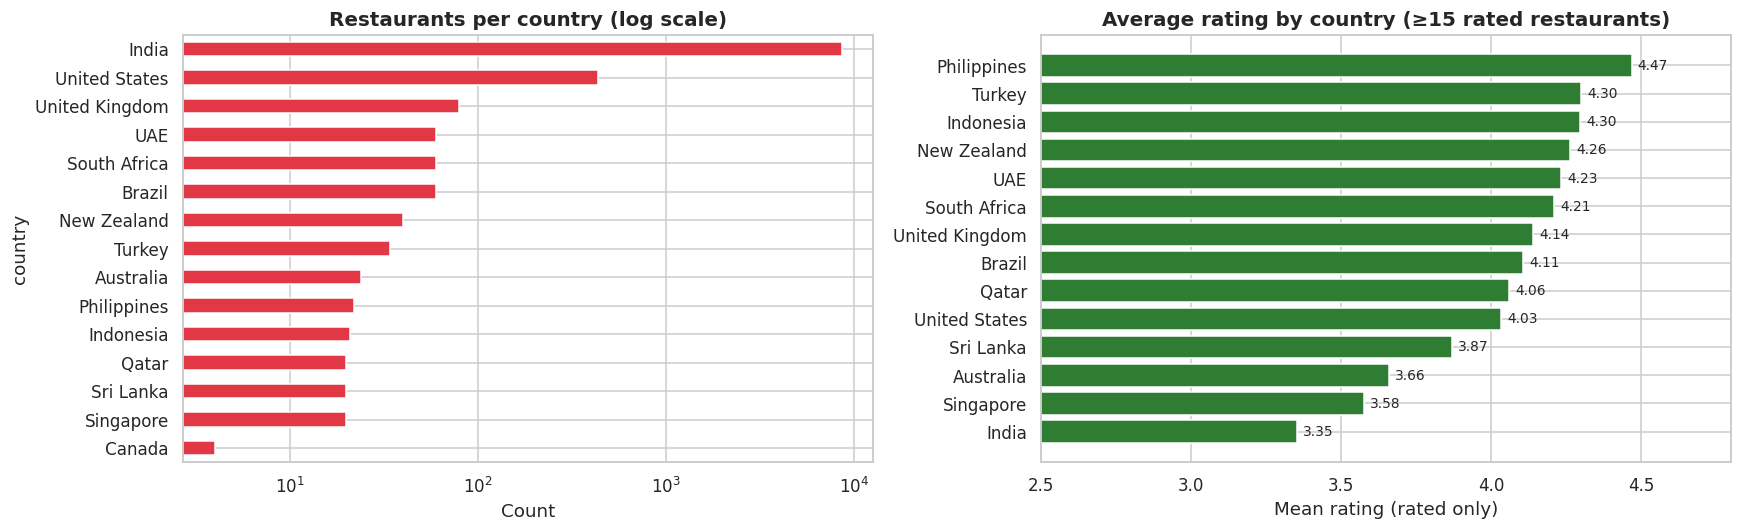

In [33]:
country_stats = summarize(df, "country",
                          online_delivery=("online_delivery", "mean"),
                          table_booking=("table_booking", "mean"))
country_stats = country_stats.sort_values("restaurants", ascending=False)
country_stats["share_%"] = (country_stats["restaurants"] / len(df) * 100).round(2)
display(country_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

country_stats["restaurants"].plot.barh(ax=axes[0], color=ZOMATO_RED, logx=True)
axes[0].invert_yaxis()
axes[0].set(title="Restaurants per country (log scale)", xlabel="Count")

big_countries = country_stats[country_stats["rated"] >= 15].sort_values("avg_rating")
axes[1].barh(big_countries.index, big_countries["avg_rating"], color=GREEN)
axes[1].set(title="Average rating by country (≥15 rated restaurants)", xlim=(2.5, 4.8),
            xlabel="Mean rating (rated only)")
for i, value in enumerate(big_countries["avg_rating"]):
    axes[1].text(value + 0.02, i, f"{value:.2f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

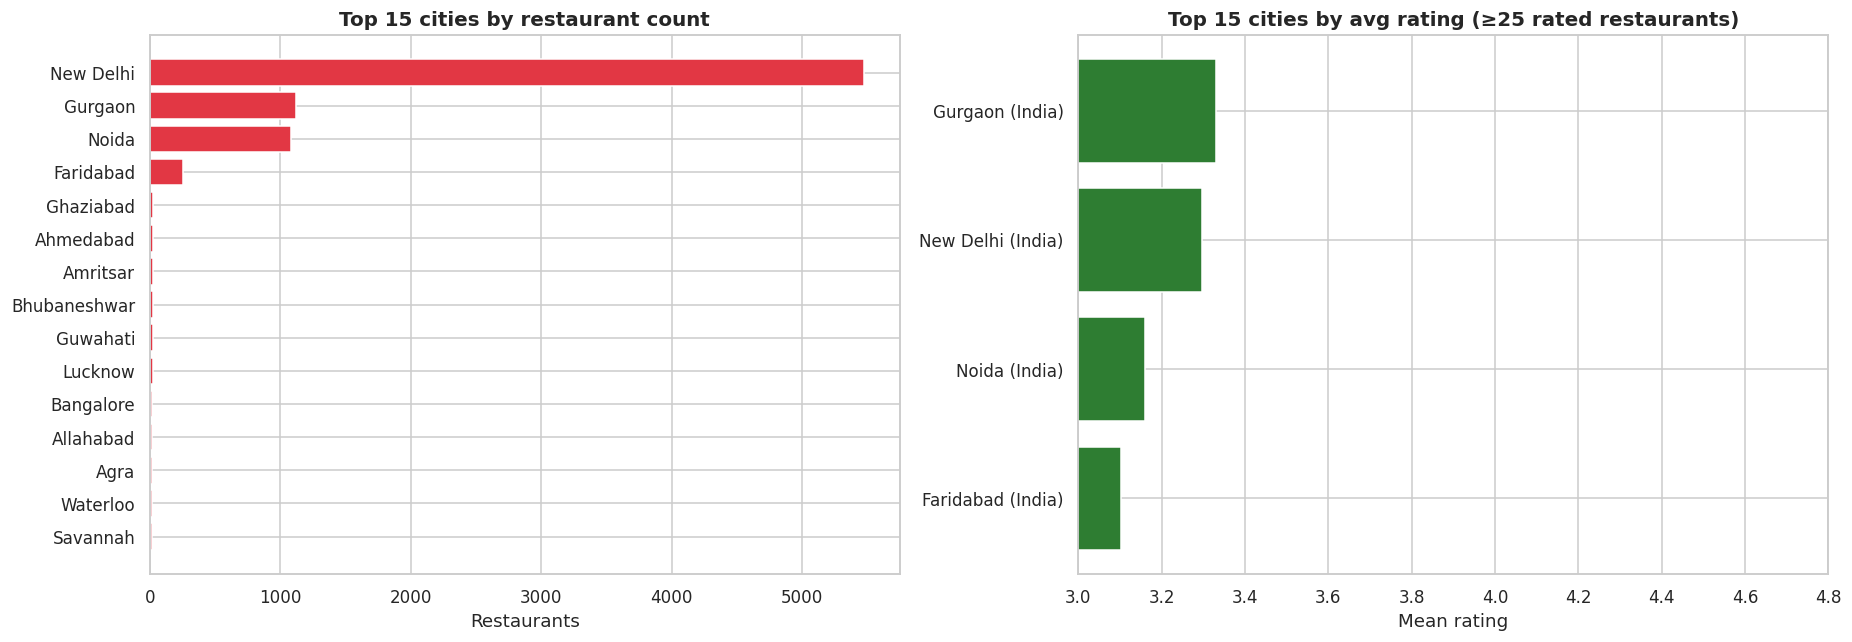

Share of India's restaurants in the Delhi NCR cities: 91.9%


In [34]:
city_stats = summarize(df, ["country", "city"]).reset_index()

top_cities = city_stats.sort_values("restaurants", ascending=False).head(15)
best_cities = city_stats[city_stats["rated"] >= 25].sort_values("avg_rating", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].barh(top_cities["city"], top_cities["restaurants"], color=ZOMATO_RED)
axes[0].invert_yaxis()
axes[0].set(title="Top 15 cities by restaurant count", xlabel="Restaurants")

axes[1].barh(best_cities["city"] + " (" + best_cities["country"] + ")", best_cities["avg_rating"], color=GREEN)
axes[1].invert_yaxis()
axes[1].set(title="Top 15 cities by avg rating (≥25 rated restaurants)", xlim=(3.0, 4.8), xlabel="Mean rating")

plt.tight_layout()
plt.show()

DELHI_NCR_CITIES = ["New Delhi", "Gurgaon", "Noida", "Faridabad", "Ghaziabad"]
print("Share of India's restaurants in the Delhi NCR cities:",
      f"{india['city'].isin(DELHI_NCR_CITIES).mean():.1%}")

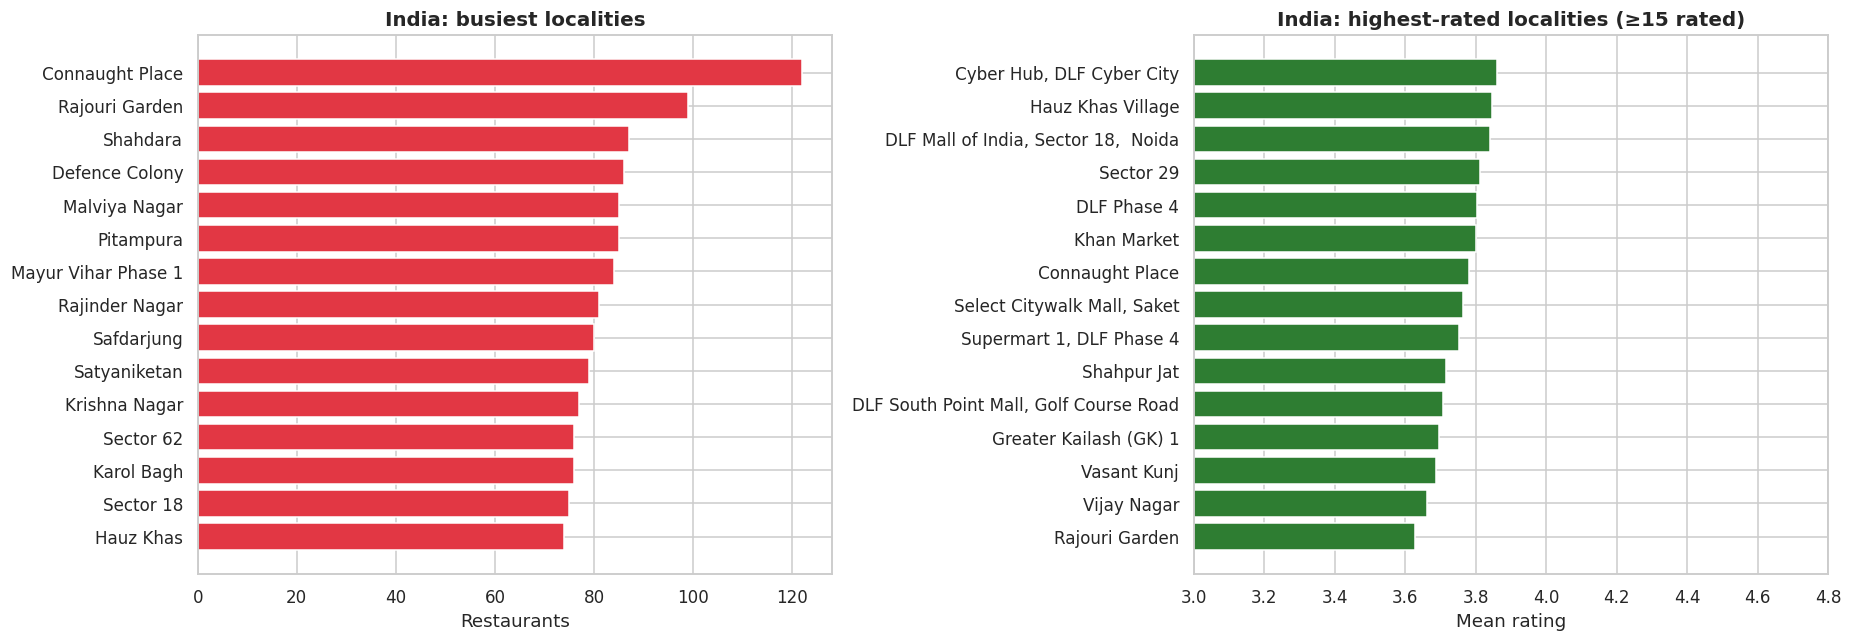

In [35]:
locality_stats = summarize(india, "locality").reset_index()

busiest_localities = locality_stats.sort_values("restaurants", ascending=False).head(15)
best_localities = locality_stats[locality_stats["rated"] >= 15].sort_values("avg_rating", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].barh(busiest_localities["locality"], busiest_localities["restaurants"], color=ZOMATO_RED)
axes[0].invert_yaxis()
axes[0].set(title="India: busiest localities", xlabel="Restaurants")

axes[1].barh(best_localities["locality"], best_localities["avg_rating"], color=GREEN)
axes[1].invert_yaxis()
axes[1].set(title="India: highest-rated localities (≥15 rated)", xlim=(3.0, 4.8), xlabel="Mean rating")

plt.tight_layout()
plt.show()

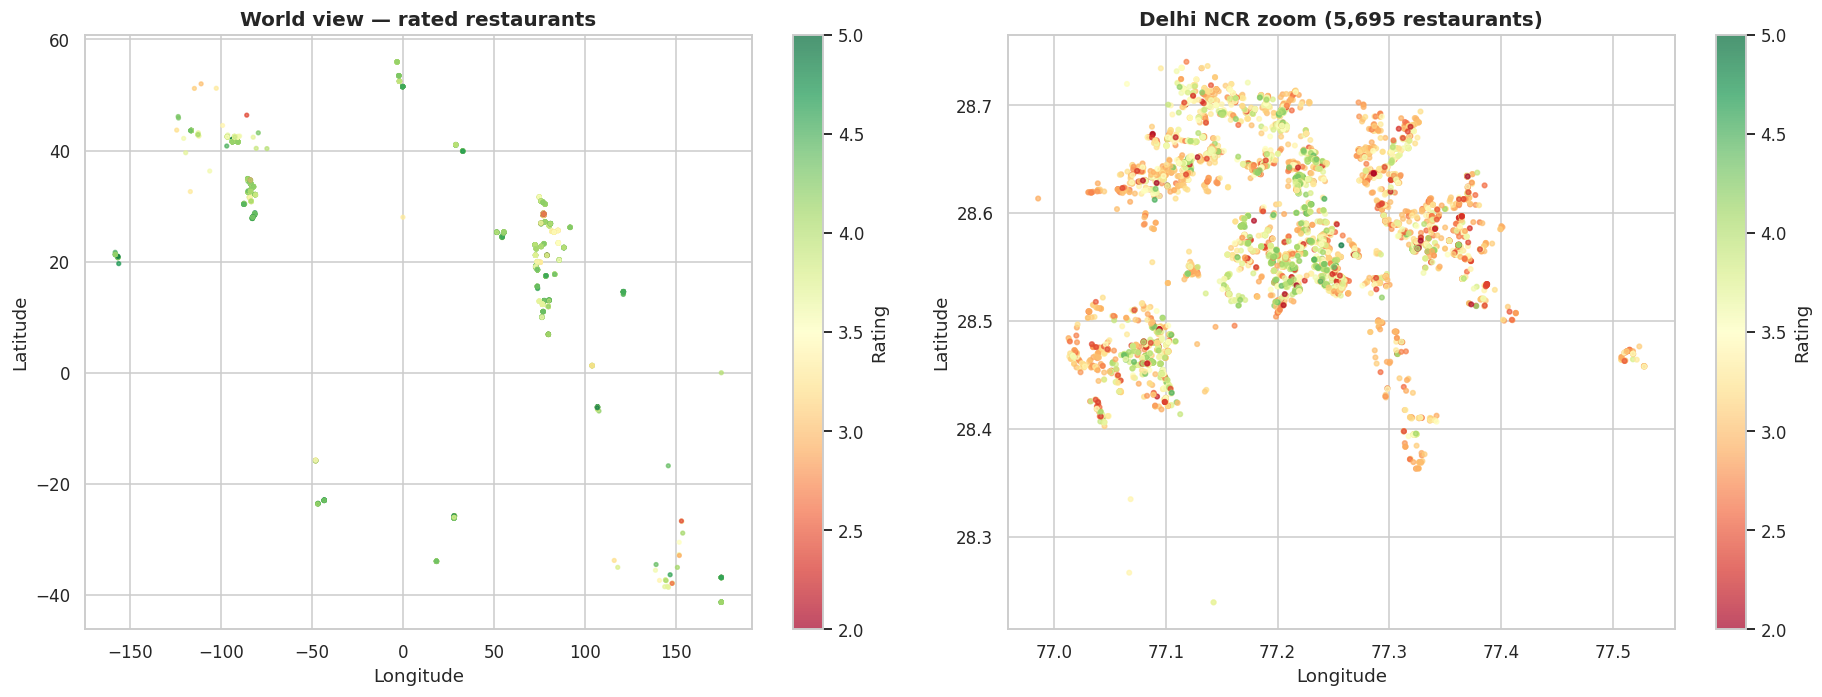

In [36]:
geo = df[df["valid_coords"] & df["is_rated"]]
ncr = geo[(geo["country"] == "India")
          & geo["longitude"].between(76.8, 77.8)
          & geo["latitude"].between(28.2, 29.0)]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

points = axes[0].scatter(geo["longitude"], geo["latitude"], c=geo["rating"],
                         cmap="RdYlGn", s=6, alpha=0.7, vmin=2, vmax=5)
axes[0].set(title="World view — rated restaurants", xlabel="Longitude", ylabel="Latitude")
plt.colorbar(points, ax=axes[0], label="Rating")

points = axes[1].scatter(ncr["longitude"], ncr["latitude"], c=ncr["rating"],
                         cmap="RdYlGn", s=9, alpha=0.7, vmin=2, vmax=5)
axes[1].set(title=f"Delhi NCR zoom ({len(ncr):,} restaurants)", xlabel="Longitude", ylabel="Latitude")
plt.colorbar(points, ax=axes[1], label="Rating")

plt.tight_layout()
plt.show()

Distinct cuisines: 145


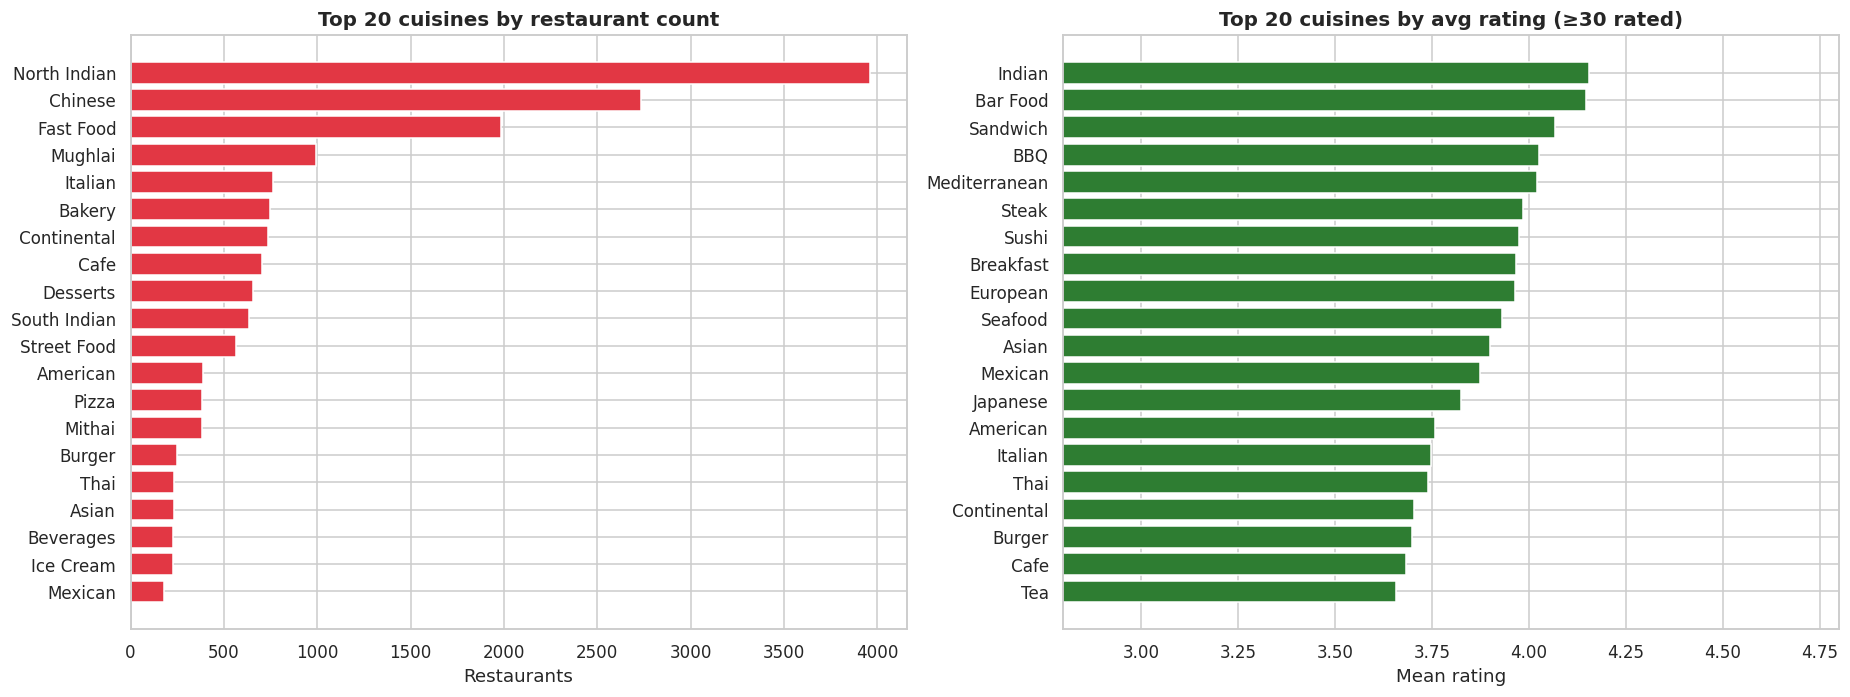

Lowest-rated popular cuisines (≥30 rated):


,restaurants,rated,avg_rating
cuisine,,,
Raw Meats,114,80,3.07
Mithai,380,251,3.14
Salad,93,91,3.24
South Indian,636,485,3.24
Fast Food,1986,1563,3.26
Mughlai,994,794,3.27
Chinese,2733,2184,3.28
Street Food,562,403,3.29


In [37]:
cuisine_rows = (df[df["n_cuisines"] > 0]
                .explode("cuisine_list")
                .rename(columns={"cuisine_list": "cuisine"}))
print("Distinct cuisines:", cuisine_rows["cuisine"].nunique())

cuisine_stats = (summarize(cuisine_rows, "cuisine", count_how="nunique",
                           delivery=("online_delivery", "mean"))
                 .sort_values("restaurants", ascending=False))

top_cuisines_table = cuisine_stats.head(20)
best_cuisines = cuisine_stats[cuisine_stats["rated"] >= 30].sort_values("avg_rating", ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

axes[0].barh(top_cuisines_table.index, top_cuisines_table["restaurants"], color=ZOMATO_RED)
axes[0].invert_yaxis()
axes[0].set(title="Top 20 cuisines by restaurant count", xlabel="Restaurants")

axes[1].barh(best_cuisines.index, best_cuisines["avg_rating"], color=GREEN)
axes[1].invert_yaxis()
axes[1].set(title="Top 20 cuisines by avg rating (≥30 rated)", xlim=(2.8, 4.8), xlabel="Mean rating")

plt.tight_layout()
plt.show()

print("Lowest-rated popular cuisines (≥30 rated):")
display(cuisine_stats[cuisine_stats["rated"] >= 30]
        .sort_values("avg_rating").head(8)[["restaurants", "rated", "avg_rating"]].round(2))

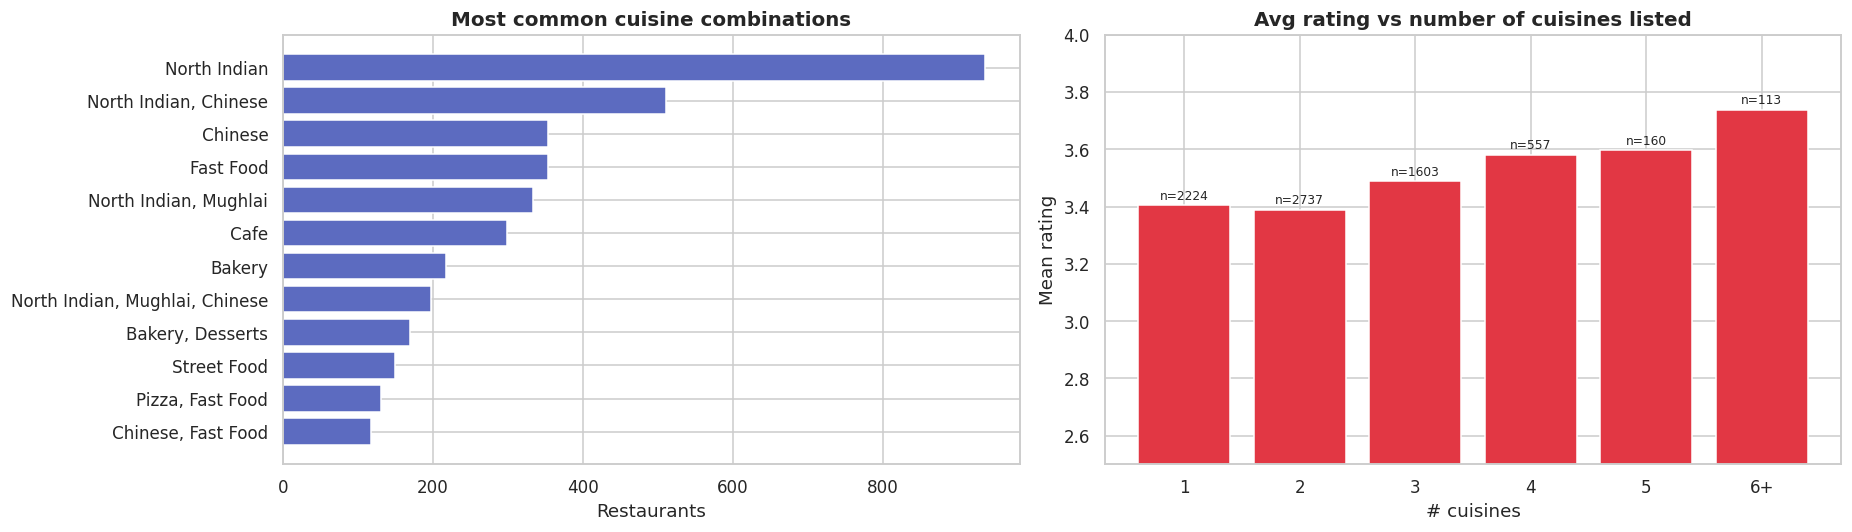

Spearman (n_cuisines vs rating): rho=0.116, p=1.7e-23


In [38]:
common_combos = df.loc[df["cuisines"] != "Unknown", "cuisines"].value_counts().head(12)

rated_with_cuisines = rated[rated["n_cuisines"] > 0]
by_n_cuisines = (rated_with_cuisines
                 .groupby(rated_with_cuisines["n_cuisines"].clip(upper=6))["rating"]
                 .agg(["mean", "count"]))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

axes[0].barh(common_combos.index, common_combos.values, color=BLUE)
axes[0].invert_yaxis()
axes[0].set(title="Most common cuisine combinations", xlabel="Restaurants")

axes[1].bar(by_n_cuisines.index.astype(str).str.replace("6", "6+"), by_n_cuisines["mean"], color=ZOMATO_RED)
for i, (mean_rating, count) in enumerate(zip(by_n_cuisines["mean"], by_n_cuisines["count"])):
    axes[1].text(i, mean_rating + 0.02, f"n={count}", ha="center", fontsize=8)
axes[1].set(title="Avg rating vs number of cuisines listed", xlabel="# cuisines",
            ylabel="Mean rating", ylim=(2.5, 4.0))

plt.tight_layout()
plt.show()

rho, p_value = stats.spearmanr(rated["n_cuisines"], rated["rating"])
print(f"Spearman (n_cuisines vs rating): rho={rho:.3f}, p={p_value:.2g}")

,mean,median,count
price_range,,,
1,3.24,3.2,2744
2,3.38,3.4,2711
3,3.78,3.8,1373
4,3.89,3.9,575


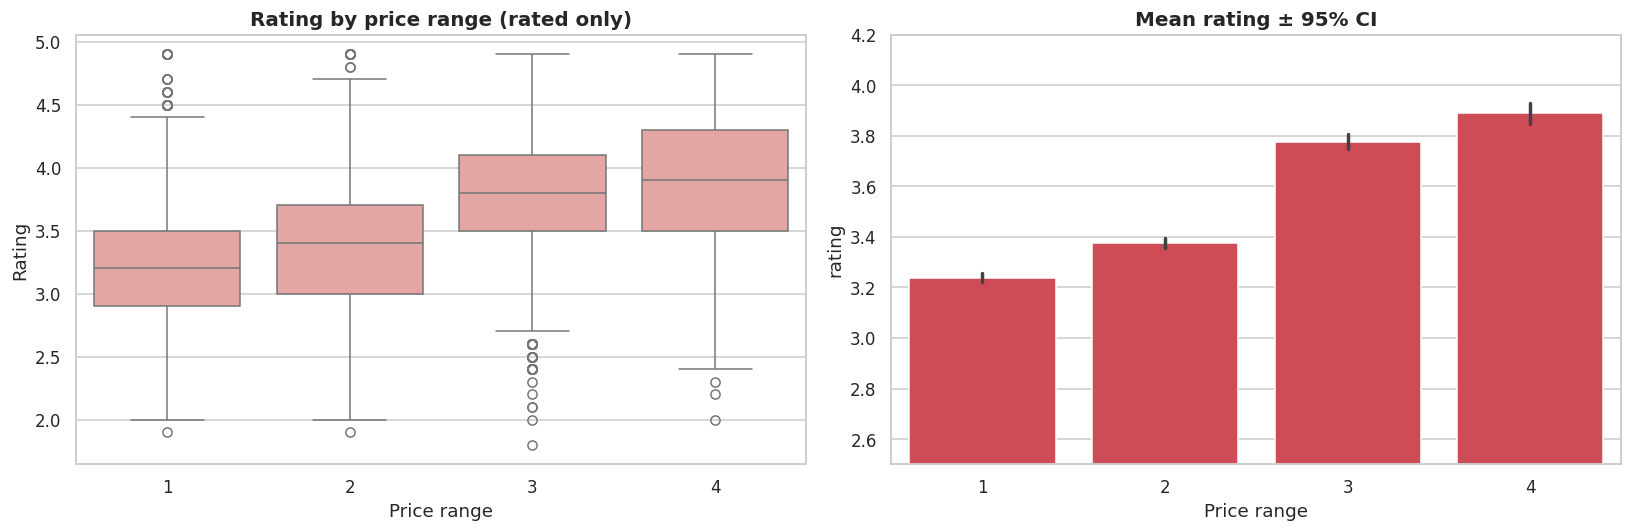

Kruskal-Wallis across price ranges: H=1326.1, p=3.2e-287


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=rated, x="price_range", y="rating", ax=axes[0], color="#EF9A9A")
axes[0].set(title="Rating by price range (rated only)", xlabel="Price range", ylabel="Rating")

display(rated.groupby("price_range")["rating"].agg(["mean", "median", "count"]).round(2))

sns.barplot(data=rated, x="price_range", y="rating", errorbar=("ci", 95), ax=axes[1], color=ZOMATO_RED)
axes[1].set(title="Mean rating ± 95% CI", ylim=(2.5, 4.2), xlabel="Price range")

plt.tight_layout()
plt.show()

ratings_by_price = [group["rating"].values for _, group in rated.groupby("price_range")]
h_stat, p_value = stats.kruskal(*ratings_by_price)
print(f"Kruskal-Wallis across price ranges: H={h_stat:.1f}, p={p_value:.2g}")

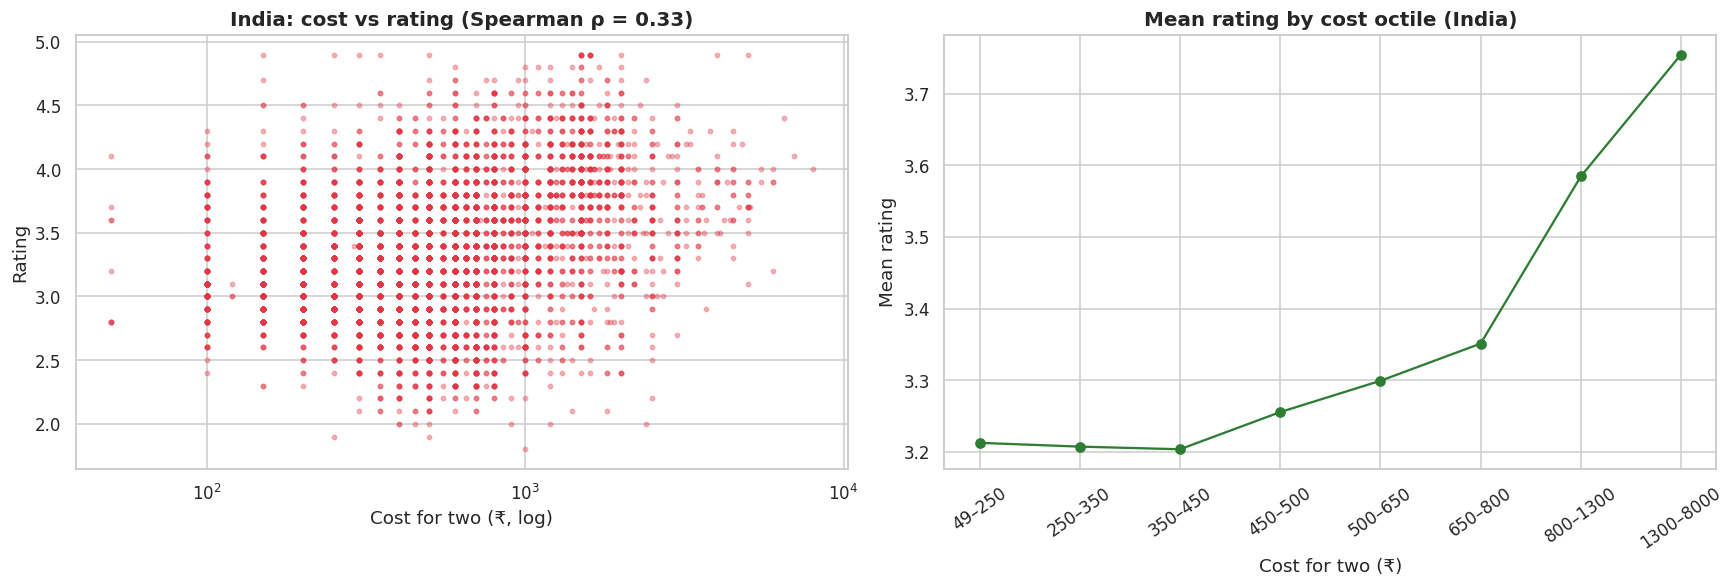

Spearman rho=0.332, p=1.7e-167


In [40]:
india_cost = india_rated[india_rated["cost_for_two"] > 0].copy()
rho, p_value = stats.spearmanr(india_cost["cost_for_two"], india_cost["rating"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].scatter(india_cost["cost_for_two"], india_cost["rating"], s=8, alpha=0.35, color=ZOMATO_RED)
axes[0].set_xscale("log")
axes[0].set(title=f"India: cost vs rating (Spearman ρ = {rho:.2f})",
            xlabel="Cost for two (₹, log)", ylabel="Rating")

india_cost["cost_bin"] = pd.qcut(india_cost["cost_for_two"], 8, duplicates="drop")
mean_by_bin = india_cost.groupby("cost_bin", observed=True)["rating"].mean()
axes[1].plot(range(len(mean_by_bin)), mean_by_bin.values, marker="o", color=GREEN)
axes[1].set_xticks(range(len(mean_by_bin)))
axes[1].set_xticklabels([f"{int(i.left)}–{int(i.right)}" for i in mean_by_bin.index], rotation=35)
axes[1].set(title="Mean rating by cost octile (India)", xlabel="Cost for two (₹)", ylabel="Mean rating")

plt.tight_layout()
plt.show()
print(f"Spearman rho={rho:.3f}, p={p_value:.2g}")

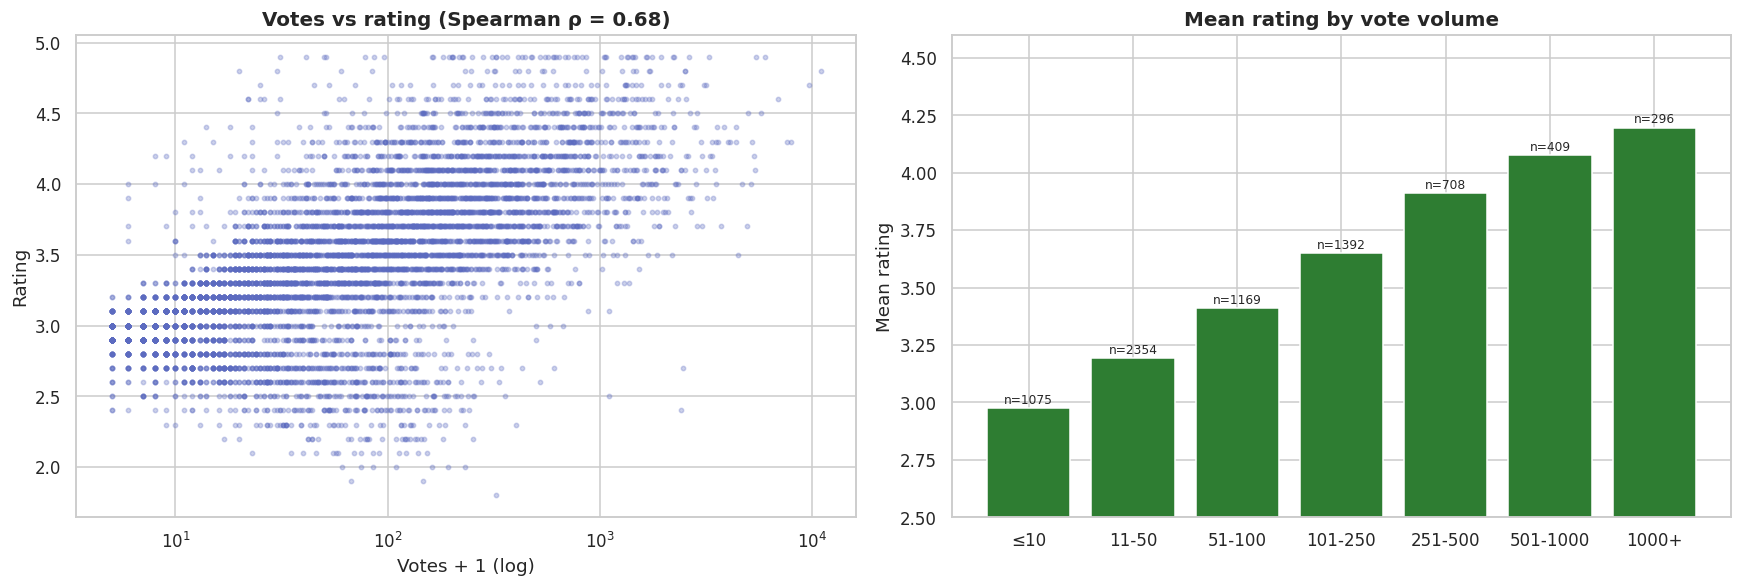

Most-voted restaurants:


,name,city,cuisines,rating,votes
728,Toit,Bangalore,"Italian, American, Pizza",4.8,10934
735,Truffles,Bangalore,"American, Burger, Cafe",4.7,9667
3994,Hauz Khas Social,New Delhi,"Continental, American, Asian, North Indian",4.3,7931
2412,Peter Cat,Kolkata,"Continental, North Indian",4.3,7574
739,AB's - Absolute Barbecues,Bangalore,"European, Mediterranean, North Indian",4.6,6907
2414,Barbeque Nation,Kolkata,"North Indian, Chinese",4.9,5966
743,Big Brewsky,Bangalore,"Finger Food, North Indian, Italian, Continenta...",4.5,5705
2307,AB's - Absolute Barbecues,Hyderabad,"European, Mediterranean, North Indian",4.9,5434
736,The Black Pearl,Bangalore,"North Indian, European, Mediterranean",4.1,5385
2411,BarBQ,Kolkata,"Chinese, North Indian",4.2,5288


In [41]:
rho, p_value = stats.spearmanr(rated["votes"], rated["rating"])

vote_bin_edges = [-1, 10, 50, 100, 250, 500, 1000, 20000]
vote_bin_labels = ["≤10", "11-50", "51-100", "101-250", "251-500", "501-1000", "1000+"]
vote_bin = pd.cut(rated["votes"], bins=vote_bin_edges, labels=vote_bin_labels)
by_vote_bin = rated.groupby(vote_bin, observed=True)["rating"].agg(["mean", "count"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].scatter(rated["votes"] + 1, rated["rating"], s=8, alpha=0.3, color=BLUE)
axes[0].set_xscale("log")
axes[0].set(title=f"Votes vs rating (Spearman ρ = {rho:.2f})", xlabel="Votes + 1 (log)", ylabel="Rating")

axes[1].bar(by_vote_bin.index.astype(str), by_vote_bin["mean"], color=GREEN)
for i, (mean_rating, count) in enumerate(zip(by_vote_bin["mean"], by_vote_bin["count"])):
    axes[1].text(i, mean_rating + 0.02, f"n={count}", ha="center", fontsize=8)
axes[1].set(title="Mean rating by vote volume", ylim=(2.5, 4.6), ylabel="Mean rating")

plt.tight_layout()
plt.show()

print("Most-voted restaurants:")
display(df.nlargest(10, "votes")[["name", "city", "cuisines", "rating", "votes"]])

,feature,with: mean rating,without: mean rating,difference,n_with,n_without,Mann-Whitney p
0,table_booking,3.5876,3.4140,0.1736,1111,6292,0.0000
1,online_delivery,3.3813,3.4674,-0.0862,2355,5048,0.0009


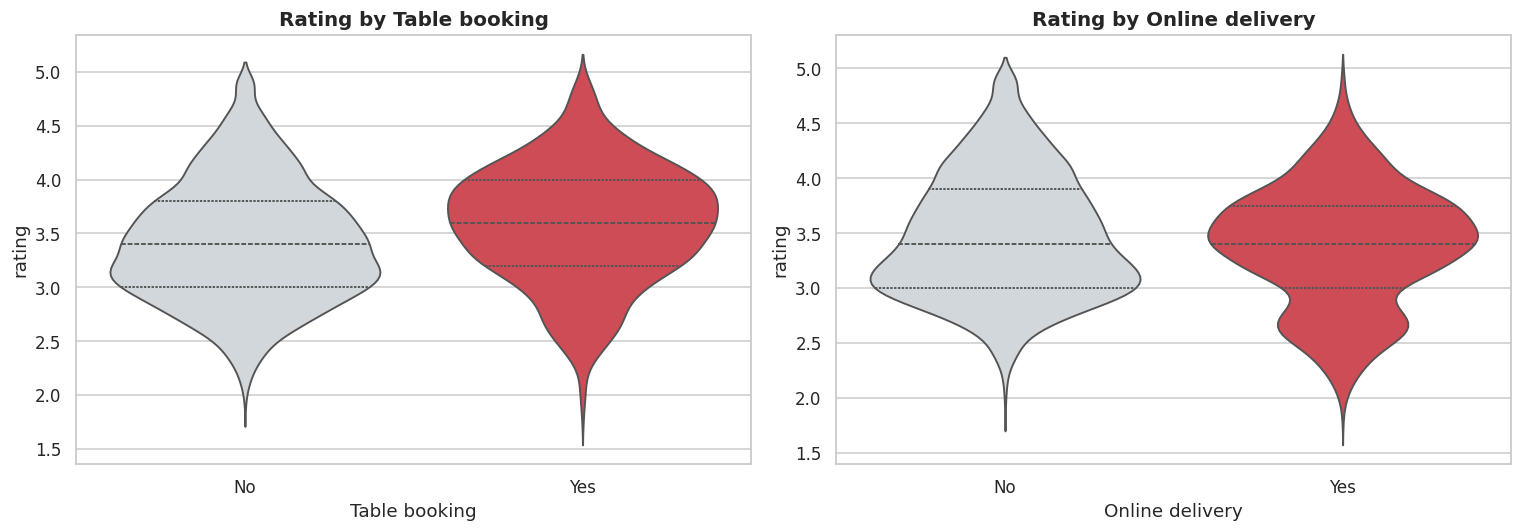

In [42]:
service_rows = []
for col in ["table_booking", "online_delivery"]:
    with_service = rated.loc[rated[col], "rating"]
    without_service = rated.loc[~rated[col], "rating"]
    _, p_value = stats.mannwhitneyu(with_service, without_service)
    service_rows.append({
        "feature": col,
        "with: mean rating": with_service.mean(),
        "without: mean rating": without_service.mean(),
        "difference": with_service.mean() - without_service.mean(),
        "n_with": len(with_service),
        "n_without": len(without_service),
        "Mann-Whitney p": p_value,
    })
display(pd.DataFrame(service_rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in zip(axes, ["table_booking", "online_delivery"], ["Table booking", "Online delivery"]):
    sns.violinplot(data=rated, x=col, y="rating", ax=ax, hue=col, legend=False,
                   palette=["#CFD8DC", ZOMATO_RED], inner="quartile")
    ax.set(title=f"Rating by {title}", xlabel=title)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No", "Yes"])

plt.tight_layout()
plt.show()

In [43]:
def rating_gap_by_price(data, feature, labels):
    """Mean rating by price range, with and without a feature, plus the gap between them."""
    table = data.pivot_table(index="price_range", columns=feature, values="rating", aggfunc="mean").round(2)
    table.columns = labels
    table["gap"] = (table[labels[1]] - table[labels[0]]).round(2)
    return table


booking_gap = rating_gap_by_price(rated, "table_booking", ["No booking", "Has booking"])
delivery_gap = rating_gap_by_price(rated, "online_delivery", ["No delivery", "Has delivery"])
display(pd.concat({"Table booking": booking_gap, "Online delivery": delivery_gap}, axis=1))

print("Share of restaurants offering each service, by price range:")
display(df.groupby("price_range")[["table_booking", "online_delivery"]].mean().mul(100).round(1))

Table booking                   Online delivery                   
               No booking Has booking   gap     No delivery Has delivery   gap
price_range                                                                   
1                    3.24        3.70  0.46            3.23         3.26  0.03
2                    3.38        3.37 -0.01            3.41         3.33 -0.08
3                    3.91        3.62 -0.29            3.83         3.65 -0.18
4                    4.05        3.70 -0.35            3.89         3.93  0.04

Share of restaurants offering each service, by price range:


,table_booking,online_delivery
price_range,,
1,0.0,15.8
2,7.7,41.3
3,45.7,29.2
4,46.8,9.0


Chains (≥5 outlets in dataset): 112 brands, 1,395 outlets


,outlets
name,
Cafe Coffee Day,83
Domino's Pizza,79
Subway,63
Green Chick Chop,51
McDonald's,48
Keventers,34
Pizza Hut,30
Giani,29
Baskin Robbins,28


,mean,median,count
is_chain,,,
Independent,3.479,3.4,6199
Chain,3.239,3.3,1204


Mann-Whitney p = 1.6e-38


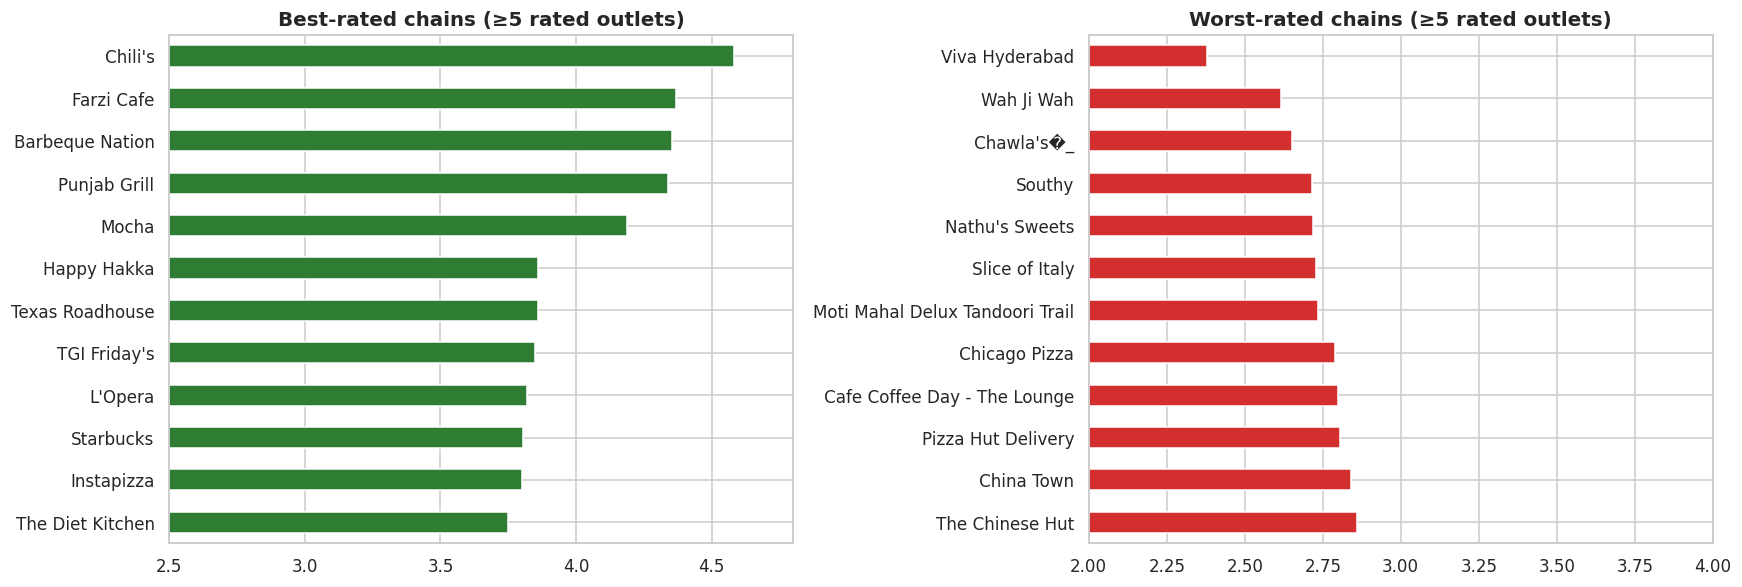

In [44]:
outlet_counts = df["name"].value_counts()
print(f"Chains (≥{CHAIN_MIN_OUTLETS} outlets in dataset): {df.loc[df['is_chain'], 'name'].nunique()} brands, "
      f"{df['is_chain'].sum():,} outlets")
display(outlet_counts.head(12).to_frame("outlets"))

chain_vs_independent = (rated.groupby("is_chain")["rating"].agg(["mean", "median", "count"])
                        .rename(index={True: "Chain", False: "Independent"}).round(3))
display(chain_vs_independent)

_, p_value = stats.mannwhitneyu(rated.loc[rated["is_chain"], "rating"],
                                rated.loc[~rated["is_chain"], "rating"])
print(f"Mann-Whitney p = {p_value:.2g}")

chain_stats = (rated[rated["is_chain"]]
               .groupby("name")
               .agg(outlets=("id", "count"), avg_rating=("rating", "mean"), avg_votes=("votes", "mean"))
               .query(f"outlets >= {CHAIN_MIN_OUTLETS}")
               .sort_values("avg_rating", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

chain_stats.head(12).iloc[::-1]["avg_rating"].plot.barh(ax=axes[0], color=GREEN)
axes[0].set(title="Best-rated chains (≥5 rated outlets)", xlim=(2.5, 4.8), ylabel="")

chain_stats.tail(12)["avg_rating"].plot.barh(ax=axes[1], color=RED)
axes[1].set(title="Worst-rated chains (≥5 rated outlets)", xlim=(2.0, 4.0), ylabel="")

plt.tight_layout()
plt.show()

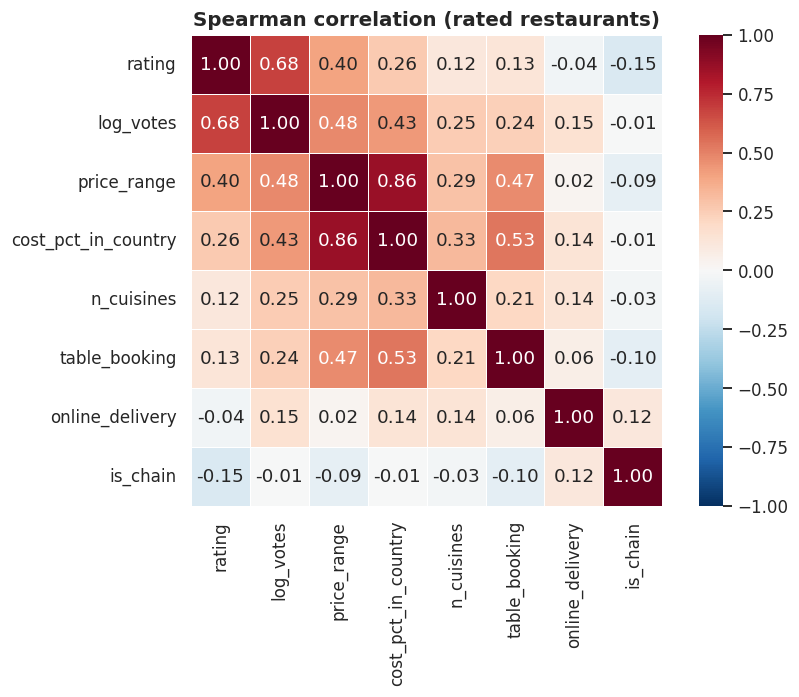

In [45]:
corr_features = pd.DataFrame({
    "rating": rated["rating"],
    "log_votes": np.log1p(rated["votes"]),
    "price_range": rated["price_range"],
    "cost_pct_in_country": rated["cost_pct_in_country"],
    "n_cuisines": rated["n_cuisines"],
    "table_booking": rated["table_booking"].astype(int),
    "online_delivery": rated["online_delivery"].astype(int),
    "is_chain": rated["is_chain"].astype(int),
})
corr = corr_features.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=ax, linewidths=0.5)
ax.set_title("Spearman correlation (rated restaurants)")
plt.tight_layout()
plt.show()

In [46]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance


def make_model():
    return GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                     subsample=0.8, random_state=RANDOM_STATE)


def evaluate(model, X_test, y_test):
    predictions = model.predict(X_test)
    return {
        "R²": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
    }


# ---- Features ----
top_cuisines = cuisine_stats.head(10).index.tolist()
X = pd.DataFrame({
    "log_votes": np.log1p(rated["votes"]),
    "price_range": rated["price_range"],
    "cost_pct_in_country": rated["cost_pct_in_country"],
    "table_booking": rated["table_booking"].astype(int),
    "online_delivery": rated["online_delivery"].astype(int),
    "n_cuisines": rated["n_cuisines"],
    "is_chain": rated["is_chain"].astype(int),
    "is_india": (rated["country"] == "India").astype(int),
})
for cuisine in top_cuisines:
    X["cuisine_" + cuisine.lower().replace(" ", "_")] = rated["cuisine_list"].apply(lambda items: int(cuisine in items))
y = rated["rating"]

# ---- Train and test ----
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
model = make_model().fit(X_train, y_train)

model_results = pd.DataFrame([
    {"model": "Baseline (mean)", **evaluate(baseline, X_test, y_test)},
    {"model": "Gradient Boosting", **evaluate(model, X_test, y_test)},
]).round(3)
display(model_results)

cv_scores = cross_val_score(make_model(), X, y, cv=5, scoring="r2")
print(f"5-fold CV R²: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

,model,R²,MAE,RMSE
0,Baseline (mean),-0.000,0.455,0.556
1,Gradient Boosting,0.621,0.258,0.342


5-fold CV R²: 0.529 ± 0.045


In [47]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# --- 1) Advanced Feature Engineering ---
# Target encoding city by frequency
city_freq = rated['city'].map(rated['city'].value_counts(normalize=True))

# Interaction terms
votes_price_interaction = np.log1p(rated['votes']) * rated['price_range']

X_optimized = pd.DataFrame({
    'log_votes': np.log1p(rated['votes']),
    'price_range': rated['price_range'],
    'cost_pct_in_country': rated['cost_pct_in_country'],
    'table_booking': rated['table_booking'].astype(int),
    'online_delivery': rated['online_delivery'].astype(int),
    'n_cuisines': rated['n_cuisines'],
    'is_chain': rated['is_chain'].astype(int),
    'is_india': (rated['country'] == 'India').astype(int),
    'city_freq': city_freq,
    'votes_price_interaction': votes_price_interaction
})

# Include all top 15 cuisines instead of 10
top_15_cuisines = cuisine_stats.head(15).index.tolist()
for cuisine in top_15_cuisines:
    col_name = "cuisine_" + cuisine.lower().replace(" ", "_")
    X_optimized[col_name] = rated['cuisine_list'].apply(lambda items: int(cuisine in items))

y_optimized = rated['rating']

# --- 2) Train / Test Split ---
X_train_opt, X_test_opt, y_train_opt, y_test_opt = train_test_split(
    X_optimized, y_optimized, test_size=0.2, random_state=RANDOM_STATE
)

# --- 3) Fine-Tuned Gradient Boosting Regressor ---
optimized_model = GradientBoostingRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.85,
    max_features='sqrt',
    random_state=RANDOM_STATE
)

optimized_model.fit(X_train_opt, y_train_opt)

# --- 4) Evaluation ---
predictions_opt = optimized_model.predict(X_test_opt)
r2 = r2_score(y_test_opt, predictions_opt)
mae = mean_absolute_error(y_test_opt, predictions_opt)
rmse = mean_squared_error(y_test_opt, predictions_opt) ** 0.5

print(f"Optimized Model Test R²: {r2:.3%}")
print(f"Optimized Model MAE: {mae:.4f}")
print(f"Optimized Model RMSE: {rmse:.4f}")


Optimized Model Test R²: 64.588%
Optimized Model MAE: 0.2500
Optimized Model RMSE: 0.3309


In [48]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Define a binary target: 1 if rating is >= 2.5 (Not Poor), 0 if < 2.5 (Poor)
y_class_train = (y_train_opt >= 2.5).astype(int)
y_class_test = (y_test_opt >= 2.5).astype(int)

# Train a Gradient Boosting Classifier
clf = GradientBoostingClassifier(n_estimators=150, random_state=RANDOM_STATE)
clf.fit(X_train_opt, y_class_train)

# Evaluate classification accuracy
clf_accuracy = accuracy_score(y_class_test, clf.predict(X_test_opt))
print(f"Classifier Accuracy: {clf_accuracy:.2%}")

Classifier Accuracy: 97.30%


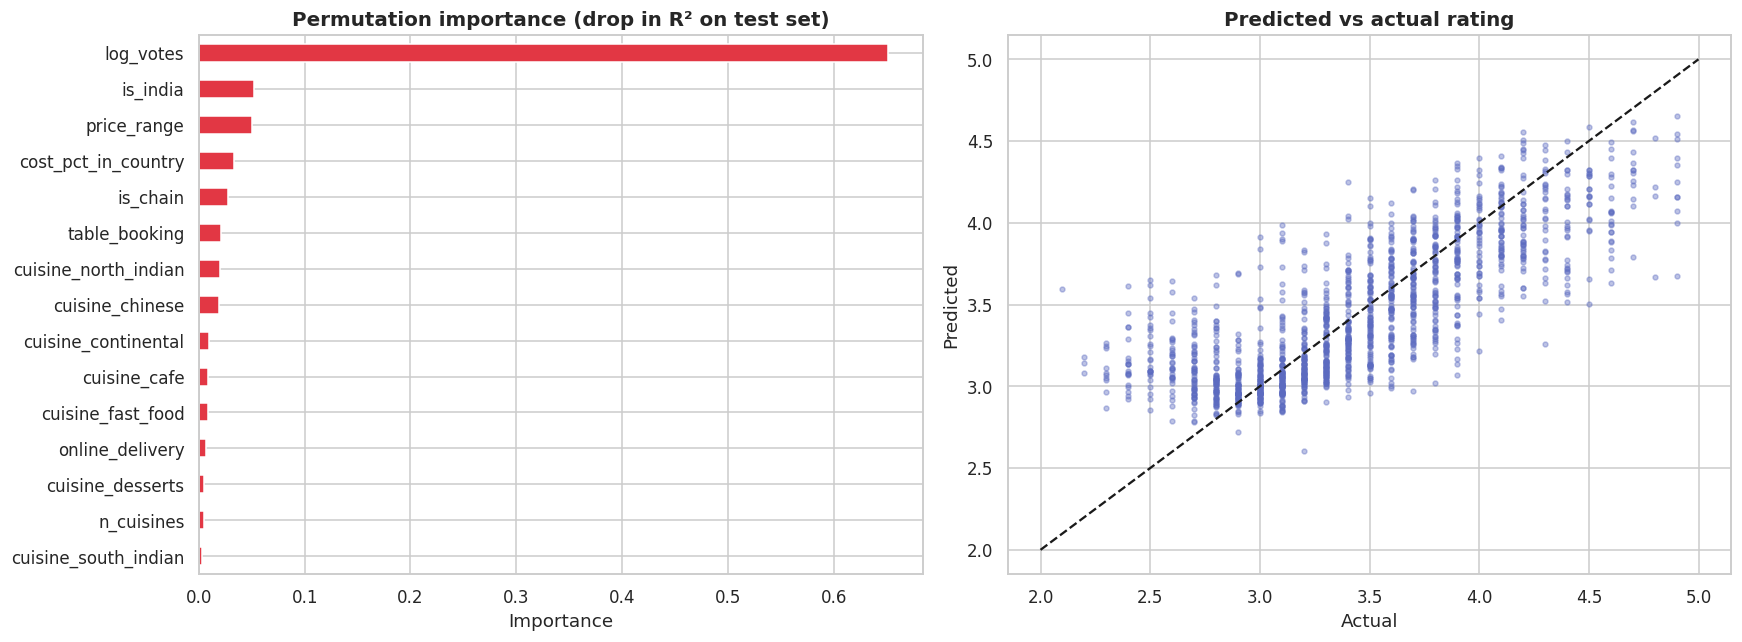

In [49]:
perm = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, scoring="r2")
importances = pd.Series(perm.importances_mean, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

importances.tail(15).plot.barh(ax=axes[0], color=ZOMATO_RED)
axes[0].set(title="Permutation importance (drop in R² on test set)", xlabel="Importance")

axes[1].scatter(y_test, model.predict(X_test), s=10, alpha=0.4, color=BLUE)
axes[1].plot([2, 5], [2, 5], "k--")
axes[1].set(title="Predicted vs actual rating", xlabel="Actual", ylabel="Predicted")

plt.tight_layout()
plt.show()

In [50]:
price_means = rated.groupby("price_range")["rating"].mean()
cost_rho = stats.spearmanr(india_cost["cost_for_two"], india_cost["rating"])[0]
votes_rho = stats.spearmanr(rated["votes"], rated["rating"])[0]
top_drivers = ", ".join(importances.sort_values(ascending=False).head(3).index)

findings = [
    f"Dataset: {len(df):,} restaurants, {df['country'].nunique()} countries, "
    f"{df['city'].nunique()} cities; India = {len(india) / len(df):.1%}.",

    f"{(~df['is_rated']).mean():.1%} of restaurants are unrated; among the rest the mean rating is "
    f"{rated['rating'].mean():.2f} (median {rated['rating'].median():.1f}).",

    f"Only {(df['rating_text'] == 'Excellent').mean():.1%} of restaurants are rated 'Excellent' (4.5+).",

    f"Most common cuisine: {cuisine_stats.index[0]} ({cuisine_stats.iloc[0]['restaurants']:.0f} restaurants); "
    f"best-rated cuisine (≥30 rated): {best_cuisines.index[0]} ({best_cuisines.iloc[0]['avg_rating']:.2f}).",

    "Price range 1 → 4 mean rating: " + " → ".join(f"{v:.2f}" for v in price_means),

    f"Votes vs rating (Spearman): {votes_rho:.2f}; India cost vs rating: {cost_rho:.2f}.",

    f"Table booking: {rated.loc[rated['table_booking'], 'rating'].mean():.2f} vs "
    f"{rated.loc[~rated['table_booking'], 'rating'].mean():.2f} without; "
    f"online delivery: {rated.loc[rated['online_delivery'], 'rating'].mean():.2f} vs "
    f"{rated.loc[~rated['online_delivery'], 'rating'].mean():.2f} without.",

    f"Chains avg {rated.loc[rated['is_chain'], 'rating'].mean():.2f} vs "
    f"independents {rated.loc[~rated['is_chain'], 'rating'].mean():.2f}.",

    f"Model: R² = {model_results.loc[1, 'R²']:.2f} (MAE {model_results.loc[1, 'MAE']:.2f} rating points); "
    f"top drivers: {top_drivers}.",
]
print("\n".join("• " + line for line in findings))

• Dataset: 9,551 restaurants, 15 countries, 141 cities; India = 90.6%.
• 22.5% of restaurants are unrated; among the rest the mean rating is 3.44 (median 3.4).
• Only 3.2% of restaurants are rated 'Excellent' (4.5+).
• Most common cuisine: North Indian (3960 restaurants); best-rated cuisine (≥30 rated): Indian (4.16).
• Price range 1 → 4 mean rating: 3.24 → 3.38 → 3.78 → 3.89
• Votes vs rating (Spearman): 0.68; India cost vs rating: 0.33.
• Table booking: 3.59 vs 3.41 without; online delivery: 3.38 vs 3.47 without.
• Chains avg 3.24 vs independents 3.48.
• Model: R² = 0.62 (MAE 0.26 rating points); top drivers: log_votes, is_india, price_range.
